# SpaceX Falcon 9 - First Stage Landing Prediction (Classification)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

In [2]:
def plot_confusion_matrix(y, y_predict, title='Confusion Matrix'):
    cm = confusion_matrix(y, y_predict)
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, ax=ax, fmt='g')
    ax.set_xlabel('Predicted labels')
    ax.set_ylabel('True labels')
    ax.set_title(title)
    ax.xaxis.set_ticklabels(['did not land', 'landed'])
    ax.yaxis.set_ticklabels(['did not land', 'landed'])
    plt.show()

In [3]:
data = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv')
X = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv')
data.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


## Task 1: Create the target array

In [4]:
Y = data['Class'].to_numpy()
Y[:10]

array([0, 0, 0, 0, 0, 0, 1, 1, 0, 0])

## Task 2: Standardize the features

In [5]:
transform = preprocessing.StandardScaler()
X = transform.fit_transform(X)
X[0:3]

array([[-1.71291154e+00, -1.94814463e-16, -6.53912840e-01,
        -1.57589457e+00, -9.73440458e-01, -1.05999788e-01,
        -1.05999788e-01, -6.54653671e-01, -1.05999788e-01,
        -5.51677284e-01,  3.44342023e+00, -1.85695338e-01,
        -3.33333333e-01, -1.05999788e-01, -2.42535625e-01,
        -4.29197538e-01,  7.97724035e-01, -5.68796459e-01,
        -4.10890702e-01, -4.10890702e-01, -1.50755672e-01,
        -7.97724035e-01, -1.50755672e-01, -3.92232270e-01,
         9.43398113e+00, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.50755672e-01, -1.05999788e-01,
        -1.05999788e-01, -1.05999788e-01, -1.05999788e-01,
        -1.05999788e-01, -1.50755672e-01, -1.05999788e-0

## Task 3: Train/test split

In [6]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print('Test samples:', Y_test.shape[0])

Test samples: 18


## Task 4: Logistic Regression

In [7]:
parameters = {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}
logreg_cv = GridSearchCV(LogisticRegression(), parameters, cv=10)
logreg_cv.fit(X_train, Y_train)
print('Best params:', logreg_cv.best_params_)
print('Validation accuracy:', logreg_cv.best_score_)

Best params: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Validation accuracy: 0.8464285714285713


## Task 5: Test accuracy and confusion matrix (Logistic Regression)

Test accuracy: 0.8333333333333334


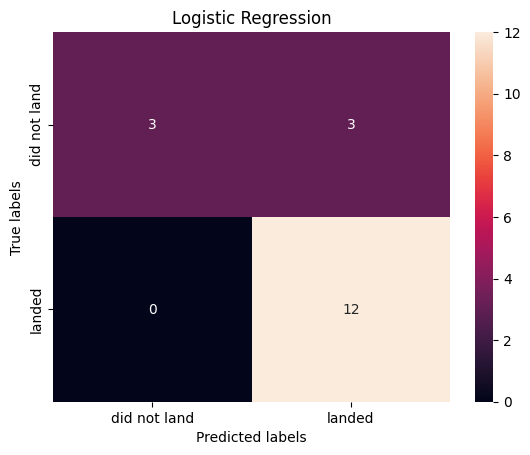

In [8]:
acc_lr = logreg_cv.score(X_test, Y_test)
print('Test accuracy:', acc_lr)
plot_confusion_matrix(Y_test, logreg_cv.predict(X_test), 'Logistic Regression')

## Task 6: Support Vector Machine

In [9]:
parameters = {'kernel': ('linear', 'rbf', 'poly', 'sigmoid'),
              'C': np.logspace(-3, 3, 5),
              'gamma': np.logspace(-3, 3, 5)}
svm_cv = GridSearchCV(SVC(), parameters, cv=10)
svm_cv.fit(X_train, Y_train)
print('Best params:', svm_cv.best_params_)
print('Validation accuracy:', svm_cv.best_score_)

Best params: {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
Validation accuracy: 0.8482142857142856


Test accuracy: 0.8333333333333334


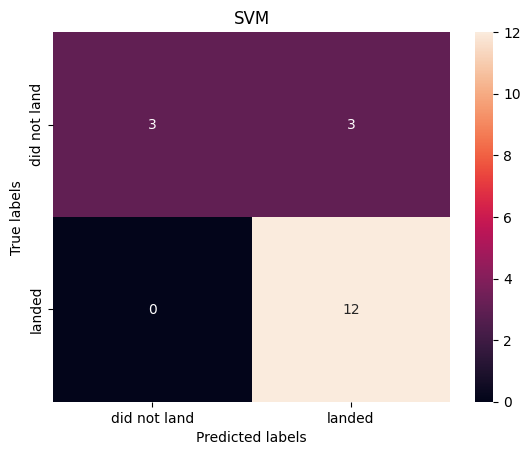

In [10]:
acc_svm = svm_cv.score(X_test, Y_test)
print('Test accuracy:', acc_svm)
plot_confusion_matrix(Y_test, svm_cv.predict(X_test), 'SVM')

## Task 8: Decision Tree

In [11]:
parameters = {'criterion': ['gini', 'entropy'],
              'splitter': ['best', 'random'],
              'max_depth': [2 * n for n in range(1, 10)],
              'max_features': ['sqrt', 'log2'],
              'min_samples_leaf': [1, 2, 4],
              'min_samples_split': [2, 5, 10]}
tree_cv = GridSearchCV(DecisionTreeClassifier(random_state=1), parameters, cv=10)
tree_cv.fit(X_train, Y_train)
print('Best params:', tree_cv.best_params_)
print('Validation accuracy:', tree_cv.best_score_)

Best params: {'criterion': 'gini', 'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'splitter': 'random'}
Validation accuracy: 0.8357142857142857


Test accuracy: 0.7777777777777778


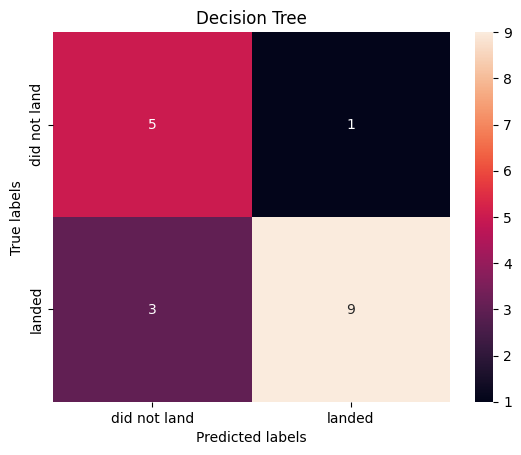

In [12]:
acc_tree = tree_cv.score(X_test, Y_test)
print('Test accuracy:', acc_tree)
plot_confusion_matrix(Y_test, tree_cv.predict(X_test), 'Decision Tree')

## Task 10: K Nearest Neighbors

In [13]:
parameters = {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
              'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
              'p': [1, 2]}
knn_cv = GridSearchCV(KNeighborsClassifier(), parameters, cv=10)
knn_cv.fit(X_train, Y_train)
print('Best params:', knn_cv.best_params_)
print('Validation accuracy:', knn_cv.best_score_)

Best params: {'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}
Validation accuracy: 0.8482142857142858


Test accuracy: 0.8333333333333334


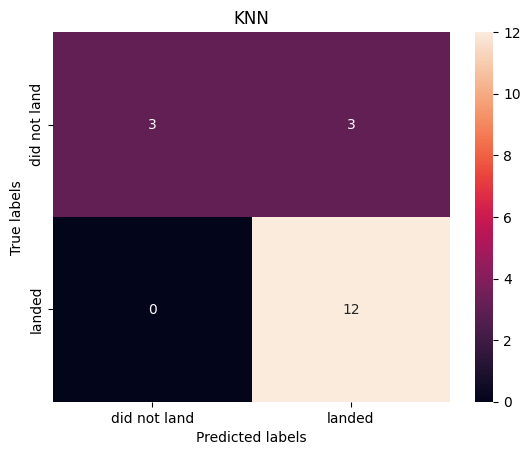

In [14]:
acc_knn = knn_cv.score(X_test, Y_test)
print('Test accuracy:', acc_knn)
plot_confusion_matrix(Y_test, knn_cv.predict(X_test), 'KNN')

## Task 12: Compare all models

                 Model  Test Accuracy  Validation Accuracy
0  Logistic Regression       0.833333             0.846429
1                  SVM       0.833333             0.848214
2        Decision Tree       0.777778             0.835714
3                  KNN       0.833333             0.848214
Best model on test data: Logistic Regression 0.8333333333333334


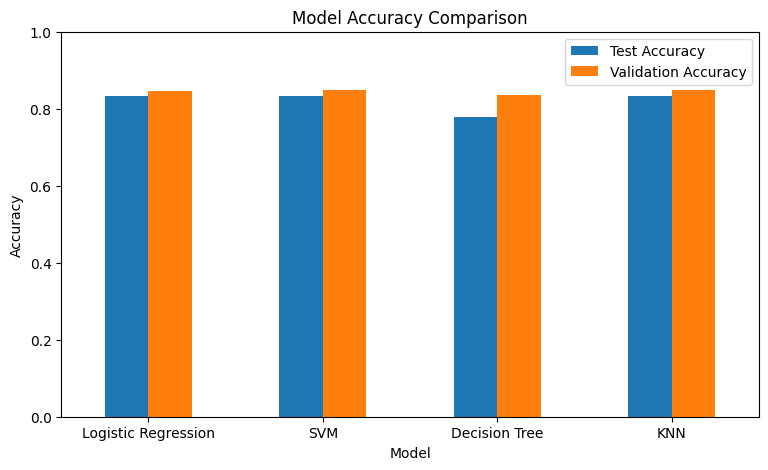

In [15]:
results = pd.DataFrame({'Model': ['Logistic Regression', 'SVM', 'Decision Tree', 'KNN'],
                        'Test Accuracy': [acc_lr, acc_svm, acc_tree, acc_knn],
                        'Validation Accuracy': [logreg_cv.best_score_, svm_cv.best_score_, tree_cv.best_score_, knn_cv.best_score_]})
print(results)
best = results.sort_values('Test Accuracy', ascending=False).iloc[0]
print('Best model on test data:', best['Model'], best['Test Accuracy'])

results.set_index('Model').plot(kind='bar', figsize=(9, 5))
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()